In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

# detect proteins containing both rewM10 and rewM13
base_dir = '../../MD_DATA'
proteins = sorted([protein for protein in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, protein, 'rewM10')) and os.path.isdir(os.path.join(base_dir, protein, 'rewM13'))])

print(f'Found {len(proteins)} proteins:')
print(proteins)


Found 47 proteins:
['AAQAA3', 'ACBP', 'ACP', 'ACTR', 'At2g44940', 'BPTI', 'Barnase', 'BarstarK60', 'BecN', 'CI2', 'Calbindin', 'CalcineurinB', 'Calmodulin', 'ChiZ', 'DAXX', 'FKBP12', 'GB3', 'GCN4', 'Galectin1', 'H14', 'HIVintegrase', 'HP36', 'Hisactophilin1', 'Im7', 'Jarastatin', 'Lactalbumin', 'Lysozyme', 'NHP2L1', 'NTail', 'PeroxiredoxinQ', 'RNaseA', 'RNaseH', 'RNaseT1', 'SAMP1', 'Staph_nuclease_P117G_H124L', 'T4_lysozyme', 'Ubiquitin', 'aSyn', 'alpha3D', 'betalactamasePSE4', 'ci2_I29A_I37H', 'd131d', 'drkN', 'fynSH3', 'hFGF1', 'lDHFR', 'plastocyanin']



rewM10 — 47 proteins
Mean ± SD across proteins:
P_SH_given_rho     = 0.923 ± 0.029
P_rho_given_SH     = 0.859 ± 0.038
Jaccard            = 0.803 ± 0.049


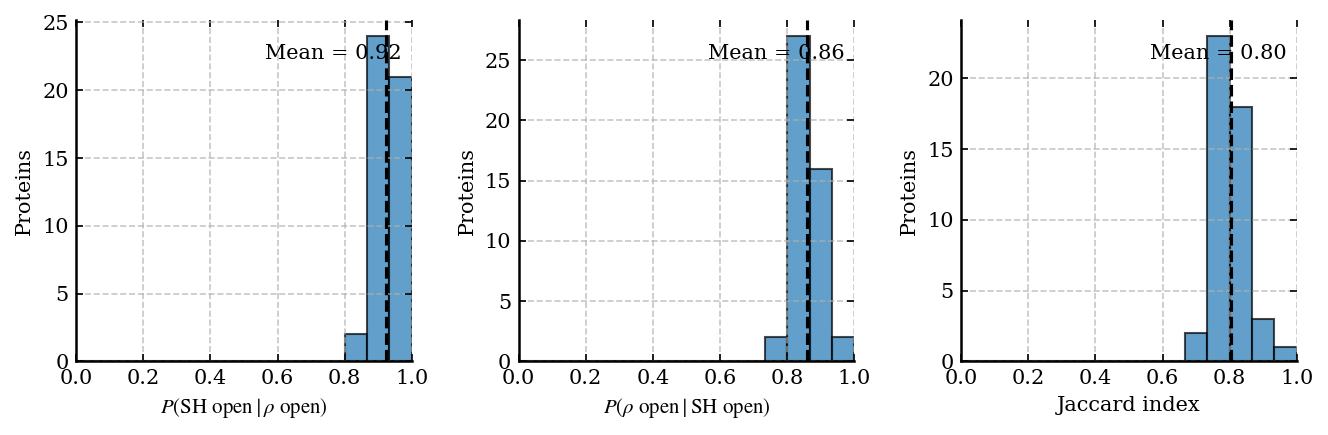


rewM13 — 47 proteins
Mean ± SD across proteins:
P_SH_given_rho     = 0.883 ± 0.038
P_rho_given_SH     = 0.899 ± 0.033
Jaccard            = 0.804 ± 0.051


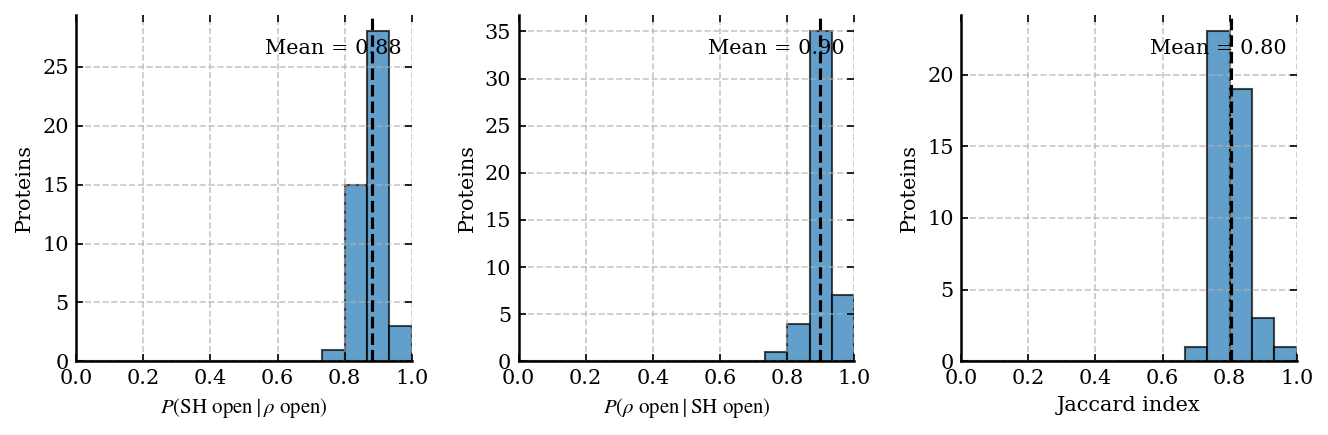


Overall summary:
 model  n_proteins  P_SH_given_rho_mean  P_SH_given_rho_std  P_rho_given_SH_mean  P_rho_given_SH_std  Jaccard_mean  Jaccard_std
rewM10          47             0.923338            0.029279             0.859442            0.037705      0.802960     0.048799
rewM13          47             0.882876            0.037694             0.899177            0.032830      0.804148     0.050578


In [10]:
rho_cutoff = 0.5
base_dir = '../../MD_DATA'

all_results = {}

for model in ['rewM10', 'rewM13']:
    results = []

    for protein in proteins:
        SH_file = f'{base_dir}/{protein}/{model}/fopen.npy'
        rho_file = f'{base_dir}/{protein}/rho_front_noexcl/rho_front_frames.npy'

        if not os.path.isfile(SH_file) or not os.path.isfile(rho_file):
            print(f'Skipping {protein} ({model}): missing file')
            continue

        SH = (np.load(SH_file).flatten() > 0).astype(int)
        rho = (np.load(rho_file).flatten() < rho_cutoff).astype(int)

        if len(SH) != len(rho):
            print(f'Skipping {protein} ({model}): lengths differ ({len(SH)} vs {len(rho)})')
            continue

        n10 = np.sum((SH == 1) & (rho == 0))
        n01 = np.sum((SH == 0) & (rho == 1))
        n11 = np.sum((SH == 1) & (rho == 1))

        p_SH_given_rho = n11 / (n01 + n11) if (n01 + n11) > 0 else np.nan
        p_rho_given_SH = n11 / (n10 + n11) if (n10 + n11) > 0 else np.nan
        jaccard = n11 / (n10 + n01 + n11) if (n10 + n01 + n11) > 0 else np.nan

        results.append({
            'protein': protein,
            'P_SH_given_rho': p_SH_given_rho,
            'P_rho_given_SH': p_rho_given_SH,
            'Jaccard': jaccard
        })

    results = pd.DataFrame(results)
    all_results[model] = results

    # save per-protein statistics
    results.to_csv(f'redundancy_stats_{model}.csv', index=False)

    # print summary
    print(f'\n{model} — {len(results)} proteins')
    print('Mean ± SD across proteins:')

    for col in ['P_SH_given_rho', 'P_rho_given_SH', 'Jaccard']:
        print(f'{col:18s} = {results[col].mean():.3f} ± {results[col].std():.3f}')

    # histograms
    metrics = {
        'P_SH_given_rho': r'$P(\mathrm{SH\ open}\mid\rho\ \mathrm{open})$',
        'P_rho_given_SH': r'$P(\rho\ \mathrm{open}\mid\mathrm{SH\ open})$',
        'Jaccard': 'Jaccard index'
    }

    fig, axes = plt.subplots(1, 3, figsize=(9, 3))

    for ax, (col, label) in zip(axes, metrics.items()):
        values = results[col].dropna()
        mean = values.mean()

        ax.hist(values, bins=15, range=(0, 1), edgecolor='black', alpha=0.7)
        ax.axvline(mean, color='black', linestyle='--', linewidth=1.5)
        ax.set_xlim(0, 1)
        ax.set_xlabel(label)
        ax.set_ylabel('Proteins')
        ax.text(0.97, 0.93, f'Mean = {mean:.2f}', transform=ax.transAxes, ha='right', va='top')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.savefig(f'redundancy_histograms_{model}.pdf', bbox_inches='tight')
    plt.show()

# save summary across models
summary = []

for model, results in all_results.items():
    row = {'model': model, 'n_proteins': len(results)}

    for col in ['P_SH_given_rho', 'P_rho_given_SH', 'Jaccard']:
        row[f'{col}_mean'] = results[col].mean()
        row[f'{col}_std'] = results[col].std()

    summary.append(row)

summary = pd.DataFrame(summary)
summary.to_csv('redundancy_stats_summary.csv', index=False)

print('\nOverall summary:')
print(summary.to_string(index=False))